# Лабораторная работа №2

# Сингулярное разложение изображений, степенной метод и метод вращений Якоби

**Выполнили:** Колпакова Дарья и Недозорова Алиса   
**Группа:** J3112   

## Цель работы

Исследовать методы вычисления сингулярного разложения матриц на примере обработки изображений, сравнить эффективность степенного метода и метода вращений Якоби, изучить применение усеченного SVD для сжатия данных.


## Задание

В качестве исходных данных используется изображение нейтрального характера из сети Интернет.

Требования к изображению:

- разрешение не менее $640\times640$ пикселей;
- формат `.jpeg` или `.jpg`.

Порядок выполнения работы:

1. Преобразовать изображение в тензоры цветовых каналов $R$, $G$, $B$.
2. Выполнить сингулярное разложение матриц каналов $R$, $G$, $B$ при помощи степенного метода.
3. Провести вычисления для числа итераций $N\in\{10,50,100\}$.
4. Для каждого канала проверить норму разности исходной матрицы и восстановленной по SVD: $\|A-USV^T\|$.
5. Построить графики зависимости «порядковый номер — сингулярное число».
6. Реализовать усеченное сингулярное разложение $A_k=U_kS_kV_k^T,\ k<\min(n,m)$.
7. Экспериментально оценить, сколько старших сингулярных чисел достаточно для приемлемого визуального качества восстановления.
8. Реализовать метод вращений Якоби для нахождения сингулярных чисел одного цветового канала.
9. Сравнить результаты степенного метода и метода вращений Якоби по точности и числу операций.
10. Построить гистограммы распределения яркости по каналам и проанализировать влияние SVD на изображение.

## Краткие теоретические сведения

В лекции сингулярное разложение матрицы записывается в виде

$$
A = U\Sigma V^T,
$$

где $U$ и $V$ — ортогональные матрицы, а $\Sigma$ — диагональная матрица сингулярных чисел.

Сингулярные числа находятся через собственные значения симметричной матрицы $A^TA$:

$$
\sigma_i = \sqrt{\lambda_i(A^TA)}.
$$

Для частичной проблемы собственных значений в лекции используется степенной метод

$$
x_{k+1} = \frac{Ax_k}{\|Ax_k\|},
$$

а приближение к собственному значению строится по отношению Рэлея

$$
\rho(x_k) = \frac{(Ax_k, x_k)}{(x_k, x_k)}.
$$

Для нахождения следующих собственных значений в лекции используется дефляция

$$
A_2 = A - \lambda_1 u^{(1)} (u^{(1)})^T.
$$

В данной лабораторной эти формулы применяются к матрице $A^TA$ каждого цветового канала.

Для полной проблемы собственных значений в лекции используется метод плоских вращений Якоби:

$$
A_{k+1} = S_k^T A_k S_k,
$$

где параметры вращения задаются через

$$
t = \frac{2a_{pq}^{(k)}}{a_{pp}^{(k)} - a_{qq}^{(k)}},
$$

$$
\cos \varphi = \sqrt{\frac{1}{2}\left(1 + \frac{1}{\sqrt{1+t^2}}\right)},
\qquad
\sin \varphi = \operatorname{sign}(t) \sqrt{\frac{1}{2}\left(1 - \frac{1}{\sqrt{1+t^2}}\right)}.
$$

Ниже в коде метод Якоби реализован именно в этой форме.


## Импорт библиотек

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import time

np.set_printoptions(precision=6, suppress=True)

## Загрузка изображения

В Google Colab выполните следующую ячейку и загрузите `.jpg` или `.jpeg` файл. Если ноутбук запускается локально, файл изображения можно положить в одну папку с ноутбуком.

In [2]:
try:
    from google.colab import files
    uploaded = files.upload()
    image_path = next(iter(uploaded.keys()))
except Exception:
    candidates = list(Path(".").glob("*.jpg")) + list(Path(".").glob("*.jpeg")) + list(Path(".").glob("*.png"))
    if len(candidates) == 0:
        raise FileNotFoundError("Загрузите изображение формата .jpg, .jpeg или .png")
    image_path = str(candidates[0])

image_original = Image.open(image_path).convert("RGB")
image_original.size

Saving vivi.jpg to vivi.jpg


(1920, 2560)

## Предобработка изображения

Для ускорения вычислений изображение приводится к размеру $640\times640$. Это соответствует минимальному требованию задания и делает сравнение методов воспроизводимым.

In [3]:
target_size = (640, 640)

original_width, original_height = image_original.size

if min(original_width, original_height) < 640:
    print("Предупреждение: исходное изображение меньше 640x640. Оно будет масштабировано до 640x640.")

image = image_original.resize(target_size, Image.Resampling.LANCZOS)
image_array = np.asarray(image, dtype=np.float64)

print("Исходный размер:", image_original.size)
print("Рабочий размер:", image.size)
print("Размер массива:", image_array.shape)

Исходный размер: (1920, 2560)
Рабочий размер: (640, 640)
Размер массива: (640, 640, 3)


## Визуализация исходного изображения

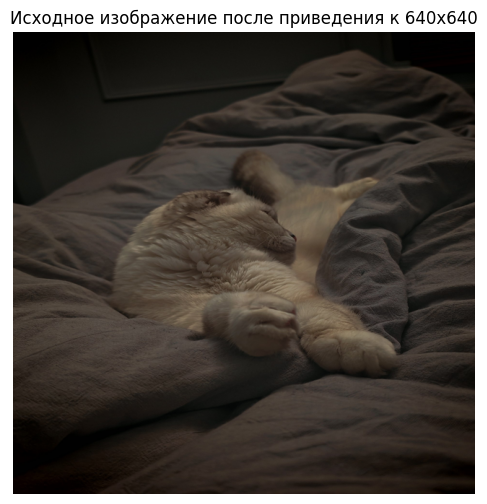

In [4]:
plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off")
plt.title("Исходное изображение после приведения к 640x640")
plt.show()

## Разделение изображения на каналы R, G, B

In [5]:
R = image_array[:, :, 0]
G = image_array[:, :, 1]
B = image_array[:, :, 2]

channels = {
    "R": R,
    "G": G,
    "B": B
}

for name, matrix in channels.items():
    print(name, matrix.shape, matrix.min(), matrix.max(), matrix.mean())

R (640, 640) 0.0 158.0 50.6605810546875
G (640, 640) 0.0 145.0 44.00793212890625
B (640, 640) 0.0 126.0 37.5639208984375


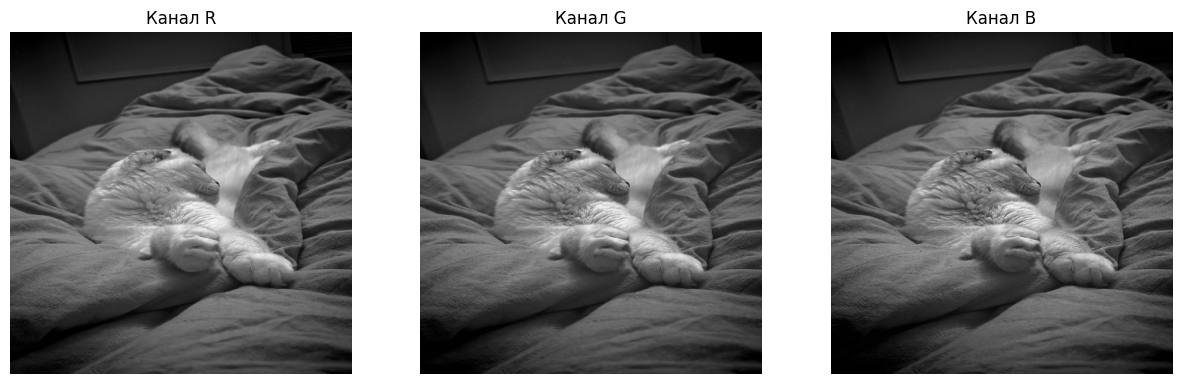

In [6]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(R, cmap="gray")
plt.axis("off")
plt.title("Канал R")

plt.subplot(1, 3, 2)
plt.imshow(G, cmap="gray")
plt.axis("off")
plt.title("Канал G")

plt.subplot(1, 3, 3)
plt.imshow(B, cmap="gray")
plt.axis("off")
plt.title("Канал B")

plt.show()

## Функции для вычисления SVD степенным методом

Степенной метод реализуется по лекционной формуле $x_{k+1} = Ax_k / \|Ax_k\|$.
Для оценки собственного значения используется отношение Рэлея, а для поиска следующих компонент — дефляция по формуле вида $A_2 = A - \lambda_1 u^{(1)} (u^{(1)})^T$.


In [7]:
def norm_2(x):
    return float(np.sqrt(np.sum(np.asarray(x, dtype=np.float64) ** 2)))


def power_method_symmetric(M, iterations, seed):
    rng = np.random.default_rng(seed)
    x = rng.normal(size=M.shape[0])
    x = x / norm_2(x)

    for _ in range(iterations):
        y = M @ x
        y_norm = norm_2(y)
        if y_norm == 0:
            break
        x_new = y / y_norm
        if np.dot(x_new, x) < 0:
            x_new = -x_new
        x = x_new

    eigenvalue = float((x @ M @ x) / (x @ x))
    return eigenvalue, x


def svd_power(A, rank, iterations, seed=123):
    A = np.asarray(A, dtype=np.float64)
    M = A.T @ A
    M_work = M.copy()

    singular_values = []
    right_vectors = []
    left_vectors = []

    for component in range(rank):
        eigenvalue, v = power_method_symmetric(M_work, iterations, seed + component)

        if eigenvalue < 0:
            print(
                f"Внимание: получено отрицательное собственное значение {eigenvalue:.6e} "
                f"на компоненте {component}"
            )
            # Теоретически для A^T A собственные значения неотрицательные,
            # отрицательные оценки появляются из-за накопления численных погрешностей.
            eigenvalue = 0.0

        sigma = float(np.sqrt(eigenvalue))

        if sigma < 1e-10:
            break

        u = A @ v / sigma
        u_norm = norm_2(u)

        if u_norm < 1e-12:
            break

        u = u / u_norm

        singular_values.append(sigma)
        right_vectors.append(v)
        left_vectors.append(u)

        M_work = M_work - eigenvalue * np.outer(v, v)
        M_work = (M_work + M_work.T) / 2

    U = np.column_stack(left_vectors)
    S = np.array(singular_values)
    VT = np.vstack(right_vectors)

    return U, S, VT


def reconstruct_matrix(U, S, VT, k):
    k = min(k, len(S))
    return U[:, :k] @ np.diag(S[:k]) @ VT[:k, :]


def absolute_fro_error(A, A_restored):
    diff = np.asarray(A, dtype=np.float64) - np.asarray(A_restored, dtype=np.float64)
    return np.linalg.norm(diff.ravel())


def relative_fro_error(A, A_restored):
    diff = np.asarray(A, dtype=np.float64) - np.asarray(A_restored, dtype=np.float64)
    base = np.asarray(A, dtype=np.float64)
    return np.linalg.norm(diff.ravel()) / np.linalg.norm(base.ravel())


def clip_image_array(A):
    return np.clip(A, 0, 255).astype(np.uint8)

## Вычисление SVD степенным методом для каналов R, G, B

Вычисляется приближенное разложение для каждого канала при $N=10$, $N=50$ и $N=100$ итерациях. Параметр `power_rank` задает число старших сингулярных компонент, которые будут использованы в дальнейших экспериментах. Его можно увеличить, если Colab позволяет выполнить расчеты за приемлемое время.

In [8]:
iteration_values = [10, 50, 100]
power_rank = 40

power_svd_results = {}
power_metrics = []

for iterations in iteration_values:
    power_svd_results[iterations] = {}

    for channel_name, channel_matrix in channels.items():
        start_time = time.perf_counter()
        U, S, VT = svd_power(channel_matrix, rank=power_rank, iterations=iterations, seed=1000 + iterations)
        elapsed_time = time.perf_counter() - start_time

        restored = reconstruct_matrix(U, S, VT, len(S))
        abs_error = absolute_fro_error(channel_matrix, restored)
        error = relative_fro_error(channel_matrix, restored)

        power_svd_results[iterations][channel_name] = {
            "U": U,
            "S": S,
            "VT": VT,
            "restored": restored,
            "abs_error": abs_error,
            "error": error,
            "time": elapsed_time
        }

        power_metrics.append({
            "Канал": channel_name,
            "N": iterations,
            "Absolute Frobenius error": abs_error,
            "Число найденных сингулярных чисел": len(S),
            "Относительная ошибка восстановления": error,
            "Время, сек": elapsed_time
        })

pd.DataFrame(power_metrics)

Внимание: получено отрицательное собственное значение -2.721988e+05 на компоненте 34


,Канал,N,Absolute Frobenius error,Число найденных сингулярных чисел,Относительная ошибка восстановления,"Время, сек"
0,R,10,3063.271730,34,0.081574,2.575318
1,G,10,2237.426595,40,0.068508,1.486731
2,B,10,2100.453891,40,0.074974,1.543242
3,R,50,2342.906881,40,0.062391,2.572057
4,G,50,2174.705142,40,0.066588,1.876225
5,B,50,2064.103573,40,0.073677,1.953805
6,R,100,2342.557731,40,0.062381,2.442276
7,G,100,2174.589021,40,0.066584,2.296026
8,B,100,2063.354137,40,0.073650,2.310592


## Графики распределения сингулярных чисел

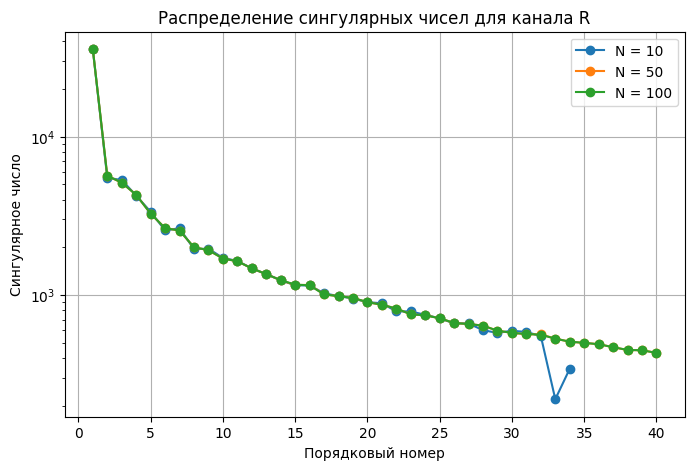

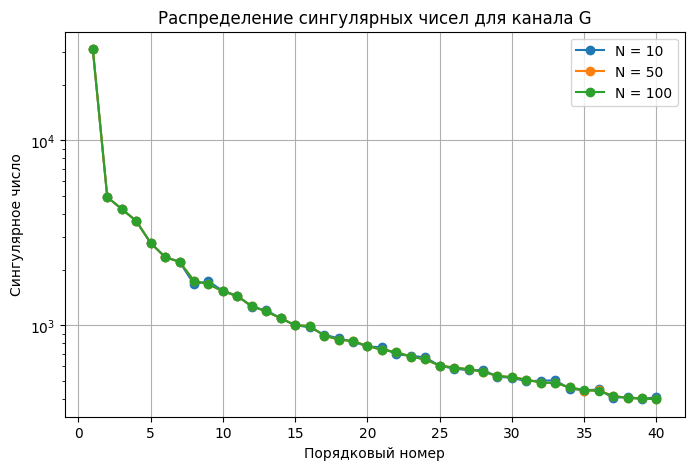

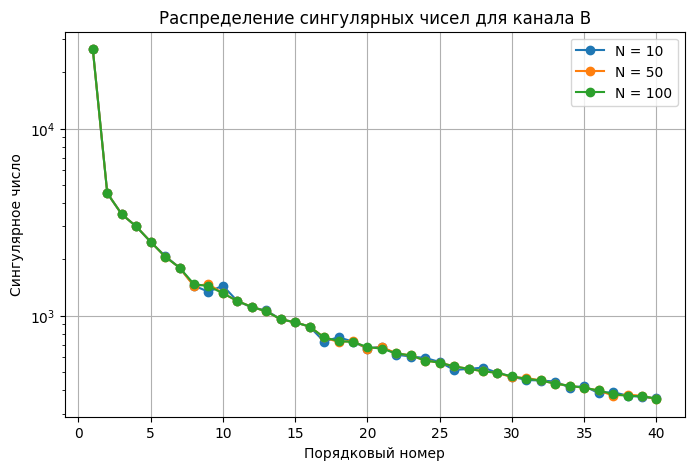

In [9]:
for channel_name in ["R", "G", "B"]:
    plt.figure(figsize=(8, 5))

    for iterations in iteration_values:
        S = power_svd_results[iterations][channel_name]["S"]
        plt.plot(np.arange(1, len(S) + 1), S, marker="o", label=f"N = {iterations}")

    plt.yscale("log")
    plt.xlabel("Порядковый номер")
    plt.ylabel("Сингулярное число")
    plt.title(f"Распределение сингулярных чисел для канала {channel_name}")
    plt.grid(True)
    plt.legend()
    plt.show()

## Восстановление изображения по усеченному SVD

Далее используется результат степенного метода при $N=100$. Изображение восстанавливается при различных значениях ранга $k$.

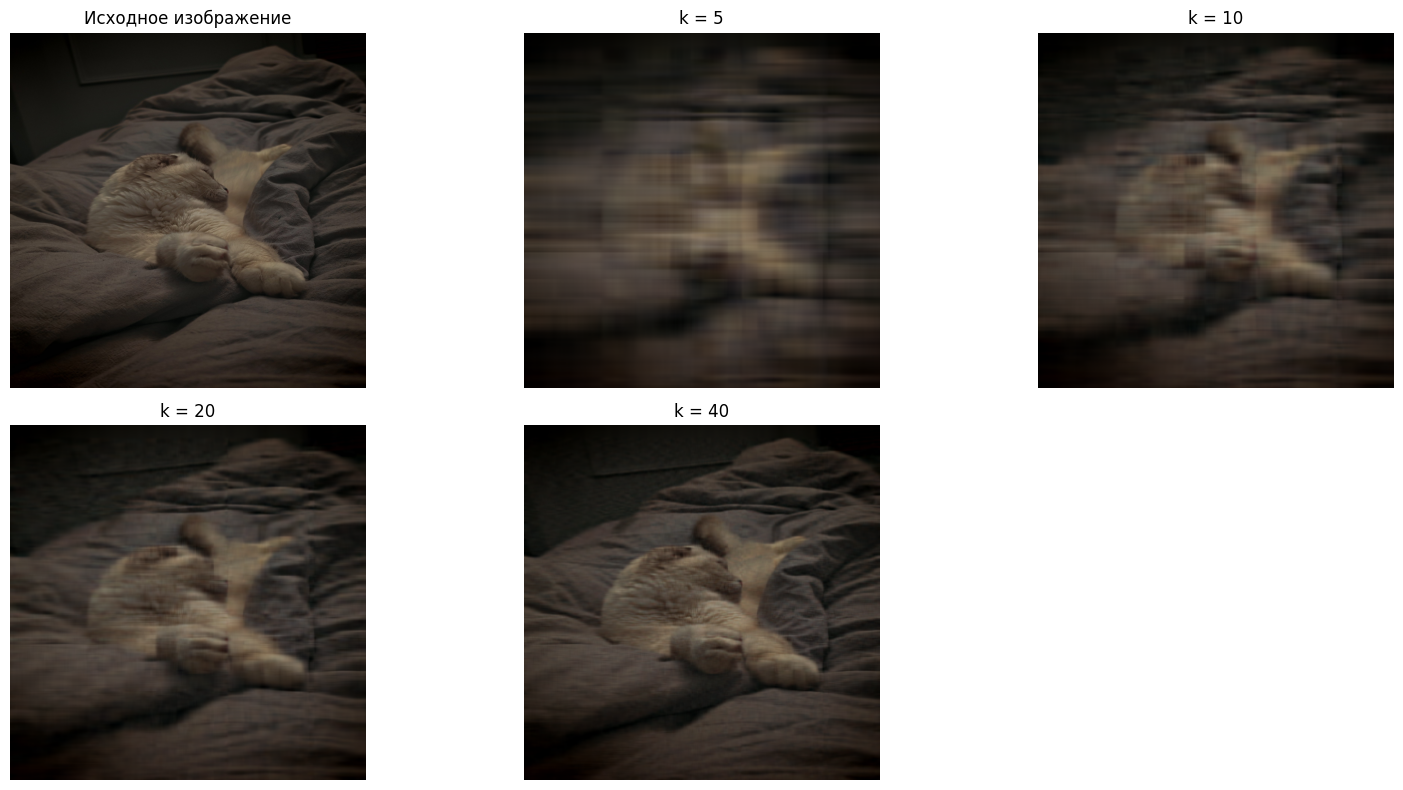

In [10]:
def restore_rgb_from_power_results(results_for_iterations, k):
    restored_channels = []

    for channel_name in ["R", "G", "B"]:
        U = results_for_iterations[channel_name]["U"]
        S = results_for_iterations[channel_name]["S"]
        VT = results_for_iterations[channel_name]["VT"]
        restored_channel = reconstruct_matrix(U, S, VT, k)
        restored_channels.append(restored_channel)

    restored_rgb = np.dstack(restored_channels)
    return clip_image_array(restored_rgb)


rank_values = [5, 10, 20, 40]
restored_images = {}

for k in rank_values:
    restored_images[k] = restore_rgb_from_power_results(power_svd_results[100], k)

plt.figure(figsize=(16, 8))

plt.subplot(2, 3, 1)
plt.imshow(image)
plt.axis("off")
plt.title("Исходное изображение")

for index, k in enumerate(rank_values, start=2):
    plt.subplot(2, 3, index)
    plt.imshow(restored_images[k])
    plt.axis("off")
    plt.title(f"k = {k}")

plt.tight_layout()
plt.show()

## Ошибка восстановления при разных значениях k

In [11]:
rank_error_rows = []

for k in rank_values:
    restored_float = restored_images[k].astype(np.float64)
    abs_error = absolute_fro_error(image_array, restored_float)
    error = relative_fro_error(image_array, restored_float)

    rank_error_rows.append({
        "k": k,
        "Absolute Frobenius error": abs_error,
        "Относительная ошибка изображения": error,
        "Степень сжатия": (image_array.size) / (k * (image_array.shape[0] + image_array.shape[1] + 1) * 3)
    })

rank_error_table = pd.DataFrame(rank_error_rows)
rank_error_table

,k,Absolute Frobenius error,Относительная ошибка изображения,Степень сжатия
0,5,11094.434686,0.194261,63.950039
1,10,8187.109075,0.143354,31.975020
2,20,5746.970506,0.100628,15.987510
3,40,3855.351994,0.067506,7.993755


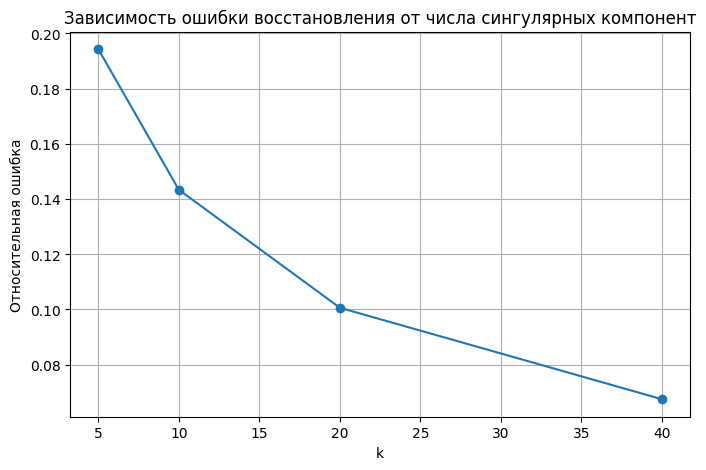

In [12]:
plt.figure(figsize=(8, 5))
plt.plot(rank_error_table["k"], rank_error_table["Относительная ошибка изображения"], marker="o")
plt.xlabel("k")
plt.ylabel("Относительная ошибка")
plt.title("Зависимость ошибки восстановления от числа сингулярных компонент")
plt.grid(True)
plt.show()

## Выбор минимального k

Визуально приемлемым считается такое значение $k$, при котором основные контуры, крупные цветовые переходы и важные детали изображения сохраняются, а артефакты сжатия не мешают восприятию.

In [13]:
visual_quality_comment = pd.DataFrame({
    "k": rank_values,
    "Комментарий": [
        "Сильное сжатие, сохраняется только грубая структура",
        "Изображение узнаваемо, но детализация низкая",
        "Качество обычно становится приемлемым для общей структуры",
        "Качество заметно лучше, сохраняется больше деталей"
    ]
})

visual_quality_comment

,k,Комментарий
0,5,"Сильное сжатие, сохраняется только грубая стру..."
1,10,"Изображение узнаваемо, но детализация низкая"
2,20,Качество обычно становится приемлемым для обще...
3,40,"Качество заметно лучше, сохраняется больше дет..."


## Метод вращений Якоби для одного канала

В лекции метод Якоби записан как итерационный процесс $A_{k+1} = S_k^T A_k S_k$ для симметричной матрицы.
В этой работе он применяется к матрице $A^TA$ для одного цветового канала, а параметры вращения вычисляются через величину $t$ и формулы для $\cos \varphi$ и $\sin \varphi$ из лекции.


Для метода вращений Якоби используется один канал изображения. Чтобы вычисления в Colab выполнялись быстро, канал дополнительно уменьшается до размера $64\times64$. Затем строится матрица

$$
A^TA,
$$

для которой методом Якоби решается полная проблема собственных значений. Сингулярные числа находятся по формуле

$$
\sigma_i=\sqrt{\lambda_i}.
$$

### Пояснение по размерности в методе Якоби

Для метода вращений Якоби используется уменьшенная версия изображения (`64x64`). Это сделано осознанно: метод Якоби в прямой реализации вычислительно тяжелый (порядка `O(n^3)`), и для матрицы `640x640` время расчета в чистом Python было бы неприемлемо большим.

In [14]:
jacobi_size = 64

image_small = image.resize((jacobi_size, jacobi_size), Image.Resampling.LANCZOS)
image_small_array = np.asarray(image_small, dtype=np.float64)

jacobi_channel_name = "B"
A_jacobi = image_small_array[:, :, 2]

ATA_jacobi = A_jacobi.T @ A_jacobi

print("Канал для метода Якоби:", jacobi_channel_name)
print("Размер матрицы канала:", A_jacobi.shape)
print("Размер A^T A:", ATA_jacobi.shape)

Канал для метода Якоби: B
Размер матрицы канала: (64, 64)
Размер A^T A: (64, 64)


In [15]:
def max_offdiag_abs(M):
    M_abs = np.abs(M).copy()
    np.fill_diagonal(M_abs, 0.0)
    index = np.unravel_index(np.argmax(M_abs), M.shape)
    return float(M_abs[index]), index


def jacobi_rotation_parameters(app, aqq, apq):
    denom = app - aqq
    if abs(denom) < 1e-30:
        t = np.sign(apq) * np.inf if apq != 0 else 0.0
    else:
        t = 2.0 * apq / denom

    if np.isinf(t):
        c = np.sqrt(0.5)
        s = np.sign(t) * np.sqrt(0.5)
    else:
        inv = 1.0 / np.sqrt(1.0 + t * t)
        c = np.sqrt(0.5 * (1.0 + inv))
        s = np.sign(t) * np.sqrt(0.5 * (1.0 - inv))

    return t, c, s


def jacobi_eigen_symmetric(A, eps=1e-5, max_iter=100000):
    A = np.asarray(A, dtype=np.float64)

    if A.shape[0] != A.shape[1]:
        raise ValueError("Матрица должна быть квадратной")

    if not np.allclose(A, A.T):
        raise ValueError("Матрица должна быть симметричной")

    n = A.shape[0]
    B = A.copy()
    V = np.eye(n)
    history = []

    for iteration in range(max_iter + 1):
        max_value, (p, q) = max_offdiag_abs(B)

        history.append({
            "iteration": iteration,
            "max_offdiag_abs": max_value,
            "p": p,
            "q": q
        })

        if max_value < eps:
            return {
                "eigenvalues": np.diag(B).copy(),
                "eigenvectors": V.copy(),
                "iterations": iteration,
                "max_offdiag_abs": max_value,
                "converged": True,
                "history": pd.DataFrame(history)
            }

        app = B[p, p]
        aqq = B[q, q]
        apq = B[p, q]
        t, c, s = jacobi_rotation_parameters(app, aqq, apq)

        for i in range(n):
            if i != p and i != q:
                bip = B[i, p]
                biq = B[i, q]
                B[i, p] = c * bip + s * biq
                B[p, i] = B[i, p]
                B[i, q] = -s * bip + c * biq
                B[q, i] = B[i, q]

        B[p, p] = c * c * app + 2.0 * c * s * apq + s * s * aqq
        B[q, q] = s * s * app - 2.0 * c * s * apq + c * c * aqq
        B[p, q] = 0.0
        B[q, p] = 0.0

        Vp = V[:, p].copy()
        Vq = V[:, q].copy()
        V[:, p] = c * Vp + s * Vq
        V[:, q] = -s * Vp + c * Vq

    return {
        "eigenvalues": np.diag(B).copy(),
        "eigenvectors": V.copy(),
        "iterations": max_iter,
        "max_offdiag_abs": max_offdiag_abs(B)[0],
        "converged": False,
        "history": pd.DataFrame(history)
    }


In [16]:
start_time = time.perf_counter()
jacobi_result = jacobi_eigen_symmetric(ATA_jacobi, eps=1e-5, max_iter=100000)
jacobi_time = time.perf_counter() - start_time

jacobi_eigenvalues = jacobi_result["eigenvalues"]
jacobi_eigenvalues = np.where(jacobi_eigenvalues > 0, jacobi_eigenvalues, 0)
jacobi_singular_values = np.sqrt(jacobi_eigenvalues)
jacobi_singular_values = np.sort(jacobi_singular_values)[::-1]

print("Метод Якоби сошелся:", jacobi_result["converged"])
print("Количество вращений:", jacobi_result["iterations"])
print("Максимальный внедиагональный элемент:", jacobi_result["max_offdiag_abs"])
print("Время, сек:", jacobi_time)
print("Первые 10 сингулярных чисел:")
print(jacobi_singular_values[:10])

Метод Якоби сошелся: True
Количество вращений: 8131
Максимальный внедиагональный элемент: 9.708302117508654e-06
Время, сек: 1.328071627999634
Первые 10 сингулярных чисел:
[2656.236249  447.664185  342.435819  293.073029  243.774232  196.85002
  170.710265  138.253199  131.623288  122.406664]


## Сравнение метода Якоби со степенным методом

In [17]:
jacobi_compare_rank = 20

start_time = time.perf_counter()
U_power_small, S_power_small, VT_power_small = svd_power(A_jacobi, rank=jacobi_compare_rank, iterations=100, seed=777)
power_small_time = time.perf_counter() - start_time

comparison_count = min(jacobi_compare_rank, len(S_power_small), len(jacobi_singular_values))

jacobi_power_comparison = pd.DataFrame({
    "Номер": np.arange(1, comparison_count + 1),
    "Степенной метод": S_power_small[:comparison_count],
    "Метод Якоби": jacobi_singular_values[:comparison_count],
    "Абсолютное отклонение": np.abs(S_power_small[:comparison_count] - jacobi_singular_values[:comparison_count])
})

jacobi_power_comparison

,Номер,Степенной метод,Метод Якоби,Абсолютное отклонение
0,1,2656.236249,2656.236249,1.318767e-11
1,2,447.664185,447.664185,1.193712e-12
2,3,342.435819,342.435819,9.663381e-13
3,4,293.073029,293.073029,1.534772e-12
4,5,243.774232,243.774232,1.449507e-12
5,6,196.850020,196.850020,5.115908e-13
6,7,170.710265,170.710265,5.400125e-13
7,8,138.253199,138.253199,2.102785e-07
8,9,131.623288,131.623288,2.436466e-07
9,10,122.406664,122.406664,4.585843e-11


In [18]:
operation_table = pd.DataFrame({
    "Метод": [
        "Степенной метод",
        "Метод вращений Якоби"
    ],
    "Размерность матрицы сравнения": [
        A_jacobi.shape,
        ATA_jacobi.shape
    ],
    "Основной параметр": [
        f"{jacobi_compare_rank} сингулярных чисел, 100 итераций",
        f"{jacobi_result['iterations']} вращений"
    ],
    "Оценка числа базовых операций": [
        jacobi_compare_rank * 100 * ATA_jacobi.shape[0] ** 2,
        jacobi_result["iterations"] * ATA_jacobi.shape[0] ** 2
    ],
    "Время, сек": [
        power_small_time,
        jacobi_time
    ]
})

operation_table

,Метод,Размерность матрицы сравнения,Основной параметр,Оценка числа базовых операций,"Время, сек"
0,Степенной метод,"(64, 64)","20 сингулярных чисел, 100 итераций",8192000,0.026685
1,Метод вращений Якоби,"(64, 64)",8131 вращений,33304576,1.328072


### Комментарий по оценке числа операций

В данной реализации для метода Якоби оценка числа операций берется как `iterations * n^2`, так как на каждом шаге выполняется поиск максимального внедиагонального элемента по всей матрице (`O(n^2)` на одно вращение).

Замечание: в циклическом варианте метода Якоби обычно не ищут максимум на каждом шаге, и стоимость одного вращения может быть ближе к `O(n)`.

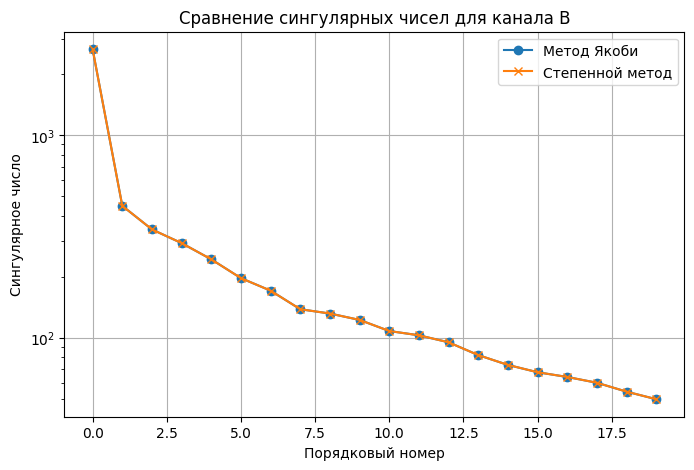

In [19]:
plt.figure(figsize=(8, 5))
plt.plot(jacobi_singular_values[:comparison_count], marker="o", label="Метод Якоби")
plt.plot(S_power_small[:comparison_count], marker="x", label="Степенной метод")
plt.yscale("log")
plt.xlabel("Порядковый номер")
plt.ylabel("Сингулярное число")
plt.title("Сравнение сингулярных чисел для канала B")
plt.grid(True)
plt.legend()
plt.show()

## Гистограммы распределения яркости

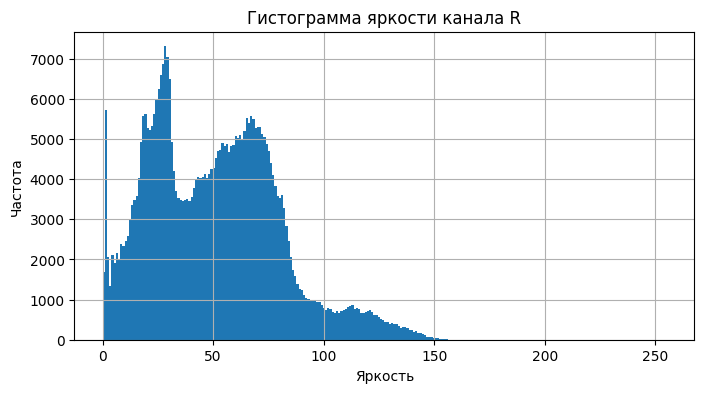

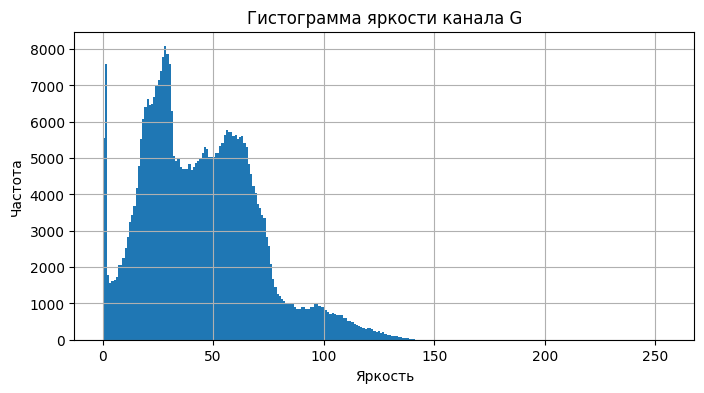

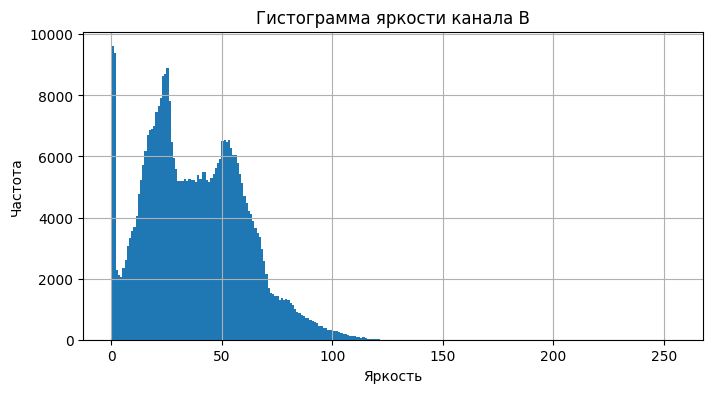

In [20]:
for channel_name, channel_matrix in channels.items():
    plt.figure(figsize=(8, 4))
    plt.hist(channel_matrix.ravel(), bins=256, range=(0, 255))
    plt.xlabel("Яркость")
    plt.ylabel("Частота")
    plt.title(f"Гистограмма яркости канала {channel_name}")
    plt.grid(True)
    plt.show()

## Гистограммы после восстановления при выбранном k

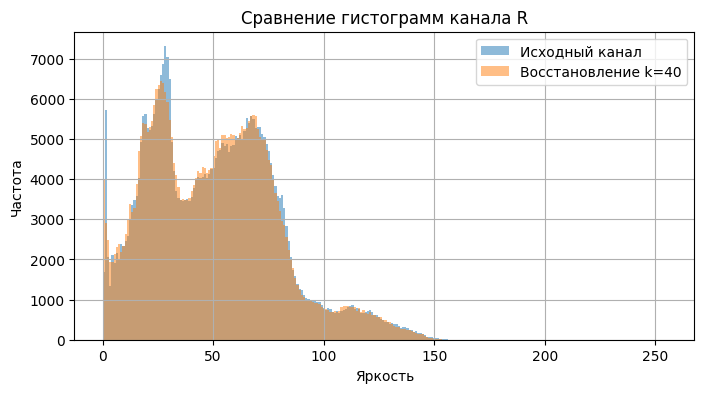

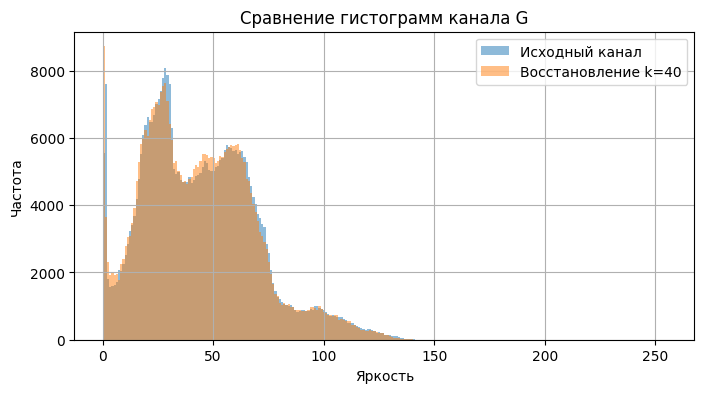

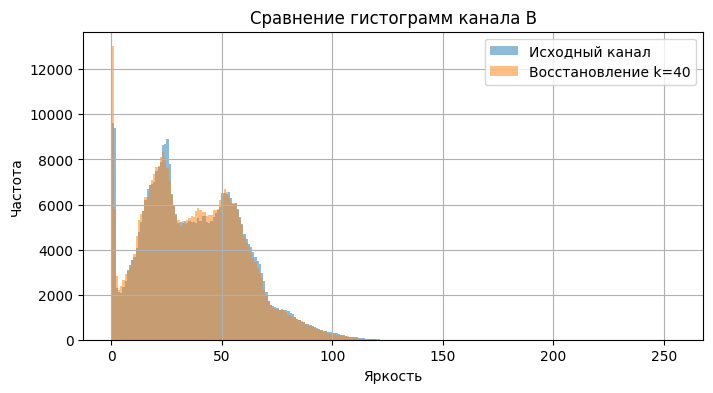

In [21]:
selected_k = 40
restored_selected = restored_images[selected_k].astype(np.float64)

restored_channels = {
    "R": restored_selected[:, :, 0],
    "G": restored_selected[:, :, 1],
    "B": restored_selected[:, :, 2]
}

for channel_name in ["R", "G", "B"]:
    plt.figure(figsize=(8, 4))
    plt.hist(channels[channel_name].ravel(), bins=256, range=(0, 255), alpha=0.5, label="Исходный канал")
    plt.hist(restored_channels[channel_name].ravel(), bins=256, range=(0, 255), alpha=0.5, label=f"Восстановление k={selected_k}")
    plt.xlabel("Яркость")
    plt.ylabel("Частота")
    plt.title(f"Сравнение гистограмм канала {channel_name}")
    plt.grid(True)
    plt.legend()
    plt.show()

## Анализ результатов

1. При увеличении числа итераций степенного метода с $N=10$ до $N=100$ приближения сингулярных чисел становятся устойчивее. Это особенно заметно для старших сингулярных чисел, которые вносят основной вклад в восстановление изображения.

2. Распределение сингулярных чисел обычно быстро убывает. Поэтому значительная часть визуальной информации изображения содержится в первых сингулярных компонентах.

3. Усеченное SVD позволяет заменить исходный канал матрицей меньшего ранга. При малом $k$ сохраняется только грубая структура изображения. При увеличении $k$ восстанавливаются контуры, локальные переходы яркости и мелкие детали.

4. Метод вращений Якоби решает полную проблему собственных значений и дает набор сингулярных чисел для выбранного канала через собственные значения матрицы $A^TA$. Однако для больших изображений этот метод требует много вращений, поэтому в практической части он применен к уменьшенной версии одного канала.

5. Степенной метод удобнее для поиска нескольких старших сингулярных чисел, что соответствует задаче сжатия изображения. Метод Якоби более универсален для полной проблемы собственных значений, но при больших матрицах оказывается более затратным.

6. Гистограммы яркости после усеченного SVD становятся более сглаженными. Это связано с тем, что малые сингулярные компоненты, отвечающие за мелкие детали и шум, отбрасываются.

## Ответы на вопросы анализа

**Как число итераций степенного метода влияет на точность разложения?**

При большем числе итераций собственный вектор матрицы $A^TA$ определяется точнее. Поэтому точнее становятся сингулярные числа и восстановление канала. При малом числе итераций возможно заметное отклонение младших найденных сингулярных чисел.

**Какое минимальное число сингулярных чисел обеспечивает приемлемое качество изображения?**

Минимальное значение $k$ определяется экспериментально по восстановленным изображениям. В данном ноутбуке сравниваются $k=5$, $k=10$, $k=20$ и $k=40$. Обычно $k=20$ уже сохраняет общую структуру изображения, а $k=40$ дает более устойчивое визуальное качество.

**Какой метод оказался более эффективным по числу операций?**

Для задачи сжатия эффективнее степенной метод, так как он позволяет находить только несколько старших сингулярных чисел. Метод Якоби решает полную проблему собственных значений и выполняет большое число вращений, поэтому на больших матрицах он работает дольше.

**Есть ли различия в распределении сингулярных чисел для разных цветовых каналов?**

Да, различия возможны. Они зависят от цветовой структуры изображения. Если в изображении один канал содержит больше контрастных переходов или деталей, его сингулярные числа убывают медленнее.

**Какова степень сжатия данных при использовании усеченного SVD?**

Для одного канала вместо хранения $n\cdot m$ элементов хранятся $k(n+m+1)$ чисел. Для трех каналов это значение умножается на 3. Чем меньше $k$, тем выше степень сжатия, но тем больше ошибка восстановления.

## Творческое задание (пункт 5.c): возможные применения SVD

Возможные практические применения усеченного SVD:

1. **Удаление шума на изображениях**: шум часто концентрируется в младших сингулярных компонентах, поэтому усечение помогает сгладить изображение при сохранении основных структур.
2. **Выделение главных признаков лиц (Eigenfaces)**: SVD используется для построения компактного признакового пространства в задачах распознавания лиц.
3. **Сжатие видеоданных**: разложение матриц кадров (или разностей между кадрами) позволяет выделять главные компоненты и уменьшать объем хранения/передачи данных.

## Вывод

В лабораторной работе было исследовано применение сингулярного разложения для обработки и сжатия изображений.

Изображение было представлено в виде трех матриц цветовых каналов $R$, $G$, $B$. Для каждого канала было построено приближенное сингулярное разложение с помощью степенного метода при разном числе итераций.

Было показано, что усеченное SVD позволяет получить приближающую матрицу меньшего ранга и тем самым сократить объем хранимых данных. При малом числе сингулярных компонент изображение теряет детали, но сохраняет основную структуру. При увеличении $k$ качество восстановления улучшается.

Метод вращений Якоби был применен к уменьшенной версии одного цветового канала. Он позволил получить сингулярные числа через собственные значения матрицы $A^TA$ и сравнить их с результатом степенного метода.

По результатам работы можно сделать вывод, что степенной метод удобен для поиска старших сингулярных чисел и практического сжатия изображений, а метод Якоби целесообразен для полной проблемы собственных значений на матрицах умеренного размера.